# ESGReady | Lab 4 · Reviewing the disclosure guidance
Run cells in order in a Python 3.11/3.12 notebook. From a fresh Colab session, unzip the project under `/content`, then run `%pip install -q -r /content/ESGReady_Lab/notebooks/week4_requirements.txt` first. If Colab requests a restart, restart the session before running this notebook. The repository contains the manifest. Restore the matching private input at `data/processed/prepared_text.jsonl` before running. The GitHub copy shows sample IDs and measurements. Full sample previews are retained in the private executed notebook. The original PDF is optional for reproducing the calculations. The completed visual review used the matching publisher snapshot.

**Part A · What must the data support?**

| Lab 2 requirement | Required evidence | Quality dimensions | Observable check and decision |
|---|---|---|---|
| FR-03. Map a question to supported disclosures with a citation. | A complete, identifiable criterion for each of eight IDs. | Completeness, accuracy | Locate every ID at its catalogue page and check the Basic-column boundaries and requested fields against the PDF. Quarantine ambiguous spans. |
| FR-04. Keep guidance and company evidence separate and expose locations and versions. | Source role, identity, version and physical page on every guidance passage. | Consistency, completeness, timeliness | Compare fields with the K1 manifest and page map. Stop on a role or locator mismatch. A version string supports traceability, while currency needs a publisher check. |

This run assesses C0 preparation for D1. One LangChain Document stores text and metadata for course compatibility. No model or API call is involved.

In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib
import json
import pickle
import re
import pandas as pd
import matplotlib.pyplot as plt
import pandera.pandas as pa
from langchain_core.documents import Document

roots = [Path.cwd(), *Path.cwd().parents, Path('/content/ESGReady_Lab')]
root = next((p for p in roots if (p / 'data/processed/prepared_text.jsonl').is_file()), None)
if root is None:
    raise FileNotFoundError('Extract the full ESGReady_Lab folder; see docs/week4_guide.md.')
data, docs = root / 'data', root / 'docs'
catalogue = {26:'E2.1', 30:'E3.1', 34:'E4.1', 46:'S2.1',
             53:'S4.1', 62:'G1.1', 65:'G2.1', 75:'G4.1'}
catalogue = {page: 'SEDG-' + code for page, code in catalogue.items()}
def digest(raw):
    return hashlib.sha256(raw).hexdigest()
def read_rows(path):
    return [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]
def save_rows(path, rows):
    path.write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in rows), encoding='utf-8')
def pack(rows):
    return [Document(page_content=r['text'], metadata=r['metadata']) for r in rows]
def verify_pair(json_path, pickle_path):
    # Only reload a pickle that this notebook just generated from the pinned input.
    rows = read_rows(json_path)
    with pickle_path.open('rb') as stream:
        chunks = pickle.load(stream)
    assert rows and len(rows) == len(chunks)
    assert all(r['text'] == c.page_content and r['metadata'] == c.metadata for r,c in zip(rows,chunks))
    assert all(r['chunk_id'] == r['metadata']['record_id'] for r in rows)
    print(f'{json_path.name} and {pickle_path.name}: {len(rows)} records, ordered IDs, text and metadata agree.')
    return rows, chunks

### A1 · Repair the Topic 3 hand-off before validation
The earlier notebook exported a flat JSONL. The course expects a JSONL with nested metadata and a PKL containing Document objects. Verify the original bytes first. Preserve every original field and record ID and add the notebook aliases `source` and `page`. Here `page` is zero-based and `pdf_page_1based` is the physical page used for citations. A changed dataset requires a new review.

In [2]:
original = data / 'processed/prepared_text.jsonl'
entry, = json.loads((data / 'week3_manifest.json').read_text())['records']
reviewed_hash = '45f826424139dd72dbe2efa8f5de2505b88e7a31e33c53dbb642ec28ae5e7680'
pdf_hash = 'c7699997922c6735ceb1ae494eb2511841c66bd03a228807ae15eba3730ace19'
assert digest(original.read_bytes()) == entry['prepared_sha256'] == reviewed_hash
assert entry['source_sha256'] == pdf_hash and entry['project_source_id'] == 'K1'
raw = read_rows(original)
records = []
for r in raw:
    metadata = {k:v for k,v in r.items() if k != 'text'}
    metadata.update(source=r['source_file'], page=r['pdf_page_1based'] - 1)
    records.append(dict(chunk_id=r['record_id'], text=r['text'], metadata=metadata))
save_rows(data / 'prepared_chunks.jsonl', records)
(data / 'chunks.pkl').write_bytes(pickle.dumps(pack(records), protocol=4))
records, chunks = verify_pair(data / 'prepared_chunks.jsonl', data / 'chunks.pkl')
for r, c in zip(raw, chunks):
    assert r == {**{k:c.metadata[k] for k in r if k != 'text'}, 'text':c.page_content}
print('Verified original JSONL SHA-256:', reviewed_hash)

prepared_chunks.jsonl and chunks.pkl: 26 records, ordered IDs, text and metadata agree.
Verified original JSONL SHA-256: 45f826424139dd72dbe2efa8f5de2505b88e7a31e33c53dbb642ec28ae5e7680


### A2 · Profile the 26 input chunks
Lengths use stripped text. Whitespace and replacement-character patterns are screening signals. The count of distinct printed disclosure IDs helps locate passages where a page label could be misleading.

In [3]:
df = pd.DataFrame([{**c.metadata, 'text':c.page_content} for c in chunks]).set_index('record_id', drop=False)
ids = df.text.str.findall(r'\bSEDG-[ESG]\d+\.\d+\b')
df['length'] = df.text.str.strip().str.len()
df['missing_text'] = df.length.eq(0)
df['missing_source'] = df.source.fillna('').str.strip().eq('')
df['bad_char'] = df.text.str.contains(r'[\x00\ufffd]')
df['space_noise'] = df.text.str.contains(r'\n{4,}| {4,}')
df['id_count'] = ids.map(lambda x: len(set(x)))
print(df[['pdf_page_1based','length','missing_text','missing_source','bad_char','space_noise','id_count']].to_string())
print(df.length.describe().round(2).to_string())

               pdf_page_1based  length  missing_text  missing_source  bad_char  space_noise  id_count
record_id                                                                                            
K1-p0026-c001               26     500         False           False     False        False         2
K1-p0026-c002               26     500         False           False     False        False         0
K1-p0026-c003               26      80         False           False     False        False         0
K1-p0030-c001               30     499         False           False     False        False         2
K1-p0030-c002               30     499         False           False     False        False         0
K1-p0030-c003               30      91         False           False     False        False         0
K1-p0034-c001               34     498         False           False     False        False         2
K1-p0034-c002               34     500         False           False     False    

### A3 · Inspect a reproducible sample
The ten records below use seed 42. Run locally to expand any full passage with `print(df.at[record_id, 'text'])`. Use the physical page and adjacent record to check continuations. The sample includes p26 c001 (two criteria), p34 c004 (a broken reference label), p53 c004 (a reference list) and p26 c002 (a meaningful continuation without an ID).

In [4]:
sample = df.sample(n=min(10,len(df)), random_state=42)
for row in sample.itertuples():
    print(row.record_id, '|', row.source, '| physical page', row.pdf_page_1based,
          '| chars', row.length, '| distinct IDs', row.id_count)
    print(row.text[:100].replace('\n', ' '))

K1-p0034-c003 | SEDG-v2.pdf | physical page 34 | chars 500 | distinct IDs 0
K1-p0053-c004 | SEDG-v2.pdf | physical page 53 | chars 247 | distinct IDs 0
K1-p0026-c001 | SEDG-v2.pdf | physical page 26 | chars 500 | distinct IDs 2
K1-p0075-c003 | SEDG-v2.pdf | physical page 75 | chars 500 | distinct IDs 0
K1-p0046-c002 | SEDG-v2.pdf | physical page 46 | chars 246 | distinct IDs 0
K1-p0034-c004 | SEDG-v2.pdf | physical page 34 | chars 3 | distinct IDs 0
K1-p0053-c001 | SEDG-v2.pdf | physical page 53 | chars 500 | distinct IDs 2
K1-p0026-c002 | SEDG-v2.pdf | physical page 26 | chars 500 | distinct IDs 0
K1-p0075-c002 | SEDG-v2.pdf | physical page 75 | chars 500 | distinct IDs 0
K1-p0030-c003 | SEDG-v2.pdf | physical page 30 | chars 91 | distinct IDs 0


| Observation | Classification and evidence | Decision |
|---|---|---|
| p26 c001 gives the reduction criterion before the consumption criterion. | Accuracy and consistency. The rendered page puts E2.1 and E2.2 in different columns. Both IDs are real. | Extract E2.1 and continue into c002 to recover the full fuel and utility list. |
| p34 c004 contains three characters. | A confirmed chunk-boundary defect for standalone retrieval. The preceding chunk and the reference table show its origin. | Keep the original for audit. Omit the reference suffix from the reviewed passage. |
| p26 c002 has no printed ID. | A valid continuation in part. It completes a fuel category and the remaining E2.1 list before the references. | Include only the verified prefix. |
| p46 c001 contains two Basic criteria on the same page. | Even a correct column filter would include S2.3 along with S2.1. | Stop at the next ID before the minimum-wage criterion. |

**Reflection.** An ID, page number and valid length can all be correct while the passage changes the meaning of a question. A length rule cannot decide if a fuel list belongs to consumption or reduction. That judgement required reading the column headings and comparing the extraction with the source.

### A4 · Run Pandera rules and retain row-level findings
Each column below represents one declared condition. Validate all conditions lazily so every failed condition is reported. A hard failure stops the release after writing the findings. The 100-character warning selects short tails for inspection against the 500-character configuration. There is no minimum length for a valid disclosure.

In [5]:
checks = pd.DataFrame(index=df.index)
checks['text_present'] = ~df.missing_text
checks['source_present'] = ~df.missing_source
checks['traceable_snapshot'] = (df.source.eq(entry['source_filename']) & df.source_id.eq('K1') &
    df.source_sha256.eq(pdf_hash) & df.source_version.eq(entry['source_version']) & df.source_url.eq(entry['source_url']))
checks['guidance_role'] = df.source_role.eq('disclosure_guidance')
checks['catalogue_page'] = df.pdf_page_1based.map(catalogue).eq(df.candidate_disclosure_id)
checks['unique_record_id'] = ~df.record_id.duplicated(keep=False)
checks['clean_characters'] = ~df.bad_char
checks['ordinary_spacing'] = ~df.space_noise
checks['length_review'] = df.length.ge(100)
checks['one_id_at_most'] = df.id_count.le(1)
review_rules = {'length_review','one_id_at_most','ordinary_spacing'}
schema = pa.DataFrameSchema({k:pa.Column(bool, pa.Check.eq(True)) for k in checks})
issues = []
try:
    schema.validate(checks, lazy=True)
except pa.errors.SchemaErrors as exc:
    for case in exc.failure_cases.to_dict('records'):
        rule, rid = case['column'], case['index']
        if rule not in checks or rid not in df.index:
            raise
        issues.append(dict(rule=rule, record_id=rid, page=int(df.at[rid,'pdf_page_1based']),
                           length=int(df.at[rid,'length']), distinct_ids=int(df.at[rid,'id_count']),
                           severity='Review' if rule in review_rules else 'Hard fail'))
columns = ['rule','record_id','page','length','distinct_ids','severity']
failures = pd.DataFrame(issues, columns=columns).sort_values(['page','record_id','rule'])
def decision(r):
    if r.rule == 'length_review':
        return 'Reference tail, outside selected criterion; exclude from reviewed text.'
    if r.rule == 'one_id_at_most':
        if r.record_id == 'K1-p0034-c001':
            return 'Advanced criteria only; exclude. Waste target starts in c002.'
        return 'Mixed IDs; retain only the visually checked target span.'
    return 'Inspect source and repair before release.'
failures['decision'] = failures.apply(decision, axis=1) if len(failures) else []
failures.to_csv(docs / 'week4_validation_failures.csv', index=False)
print((~checks).sum().to_string())
print(f'{len(failures)} rule flags across {failures.record_id.nunique()} of {len(df)} input rows.')
assert not failures.severity.eq('Hard fail').any(), 'Review hard failures before proceeding.'

text_present          0
source_present        0
traceable_snapshot    0
guidance_role         0
catalogue_page        0
unique_record_id      0
clean_characters      0
ordinary_spacing      0
length_review         5
one_id_at_most        8
13 rule flags across 13 of 26 input rows.


### B1 · Hash normalised text and keep every source location
Whitespace is collapsed only for duplicate comparison. Case and punctuation are significant. The record ledger retains all originals. Exact-normalised matches can share a representative while preserving source locations. A conflicting version would require a separate review.

In [6]:
groups = defaultdict(list)
for r in records:
    normalized = ' '.join(r['text'].split())
    groups[digest(normalized.encode())].append(r)
duplicates = []
for h, members in groups.items():
    for other in members[1:]:
        first = members[0]['metadata']
        meta = other['metadata']
        duplicates.append([h,first['record_id'],first['source'],first['pdf_page_1based'],
                           meta['record_id'],meta['source'],meta['pdf_page_1based'],
                           'Keep both source locations in lineage'])
pd.DataFrame(duplicates,columns=['hash','first_id','first_source','first_page','duplicate_id',
    'duplicate_source','duplicate_page','decision']).to_csv(docs/'week4_duplicate_review.csv',index=False)
print('Before:',len(records),'Distinct:',len(groups),'Duplicate occurrences:',len(duplicates))

Before: 26 Distinct: 26 Duplicate occurrences: 0


### B1 · Repair the bounded K1 catalogue
The review compared all eight Basic entries and the printed page labels with the publisher's PDF bearing the Lab 3 SHA-256. The following extraction boundaries apply only to this snapshot. The waste criterion begins in c002. The energy and water entries cross the c001–c002 boundary. Combining the exact original slices before normalising whitespace restores split words. All unselected portions stay in the immutable Lab 3 export.

The clean metadata adds the reviewed criterion ID, criterion origin, ordered parent IDs and exact half-open Unicode character offsets `[start,end)`. The old candidate ID remains a navigation hint.

In [7]:
assert len(groups) == len(records), 'New duplicate group requires the source-location review to be repeated.'
boundaries = {26:(1,2,'\nRELATED REFERENCES'), 30:(1,2,'\nDISCLOSURES'),
              34:(2,2,'\nDISCLOSURES'), 46:(1,1,'\n SEDG-S2.3'),
              53:(1,1,'\nDISCLOSURES'), 62:(1,1,'\nDISCLOSURES'),
              65:(1,1,'\nDISCLOSURES'), 75:(1,1,'\nDISCLOSURES')}
cleaned = []
parents_used = set()
for page, target in catalogue.items():
    first, last, stop_marker = boundaries[page]
    parent_ids = [f'K1-p{page:04d}-c{i:03d}' for i in range(first,last+1)]
    spans, pieces = [], []
    for i, rid in enumerate(parent_ids):
        s = df.at[rid,'text']
        start = s.index(target) if i == 0 else 0
        end = s.index(stop_marker,start) if i == len(parent_ids)-1 else len(s)
        spans.append(dict(record_id=rid,start=start,end=end))
        pieces.append(s[start:end])
    passage = ' '.join(''.join(pieces).split())
    assert re.findall(r'SEDG-[ESG]\d+\.\d+', passage) == [target]
    original_meta = records[df.index.get_loc(parent_ids[0])]['metadata']
    metadata = {**original_meta, 'record_id':f'K1-v2-{target}', 'reviewed_disclosure_id':target,
                'criterion_origin':'guidance', 'review_scope':'Basic criterion text, pinned K1',
                'week4_processing':'reviewed source spans, then whitespace normalization',
                'parent_spans':spans}
    cleaned.append(dict(chunk_id=metadata['record_id'],text=passage,metadata=metadata))
    parents_used.update(parent_ids)
save_rows(data/'prepared_chunks_clean.jsonl', cleaned)
(data/'chunks_clean.pkl').write_bytes(pickle.dumps(pack(cleaned), protocol=4))
ledger = df[['record_id','source','pdf_page_1based','candidate_disclosure_id']].copy()
ledger['action'] = ['Retain selected span(s)' if rid in parents_used else 'Omit from clean set; preserved in original'
                    for rid in ledger.record_id]
ledger.to_csv(docs/'week4_source_dispositions.csv',index=False)
print('Selected parent chunks:',len(parents_used),'Unused parent chunks:',len(raw)-len(parents_used))

Selected parent chunks: 10 Unused parent chunks: 16


### Source comparison · Validate each final passage against its PDF column
The review used the first (Basic) column on each pinned page. Training has a second Basic ID, so its lower boundary is the next disclosure heading. The comparison below uses page coordinates independently of the Lab 3 extraction order. It ignores whitespace only. To repeat this optional check, put the matching publisher PDF in `data/raw/SEDG-v2.pdf`. Column coordinates in PDF points belong to this layout and version only.

In [8]:
source_pdf = data/'raw/SEDG-v2.pdf'
if source_pdf.is_file():
    import pymupdf
    assert digest(source_pdf.read_bytes()) == pdf_hash
    with pymupdf.open(source_pdf) as pdf:
        for r in cleaned:
            meta = r['metadata']
            page = pdf[meta['pdf_page_1based'] - 1]
            target = meta['reviewed_disclosure_id']
            anchor, = page.search_for(target)
            stop_text = 'SEDG-S2.3' if target == 'SEDG-S2.1' else 'RELATED REFERENCES'
            stop, = page.search_for(stop_text)
            words = page.get_text('words', sort=True)
            column = ' '.join(w[4] for w in words
                              if 78 < w[0] < 225 and w[2] < 234 and anchor.y0-2 <= w[1] < stop.y0-2)
            assert ''.join(column.split()) == ''.join(r['text'].split()), target
            print(target, 'matches Basic-column source words on physical page', meta['pdf_page_1based'])
else:
    print('PDF comparison skipped on this run. See the dated review in report section 3.')

SEDG-E2.1 matches Basic-column source words on physical page 26
SEDG-E3.1 matches Basic-column source words on physical page 30
SEDG-E4.1 matches Basic-column source words on physical page 34
SEDG-S2.1 matches Basic-column source words on physical page 46
SEDG-S4.1 matches Basic-column source words on physical page 53
SEDG-G1.1 matches Basic-column source words on physical page 62
SEDG-G2.1 matches Basic-column source words on physical page 65
SEDG-G4.1 matches Basic-column source words on physical page 75


### B2 · Measure coverage against the project scope
Adequate D1 coverage means one complete Basic criterion from the authoritative K1 page for each selected ID. Equal raw chunk counts would add no assurance. The page candidate is an observed Lab 3 field. The pillar is derived from its E/S/G prefix. The reviewed ID is a new, visually checked field. K2/K3 and company evidence are separate planned collections.

disclosure  physical_page pillar  input_chunks  literal_target_chunks  reviewed_passages
 SEDG-E2.1             26      E             3                      1                  1
 SEDG-E3.1             30      E             3                      1                  1
 SEDG-E4.1             34      E             4                      1                  1
 SEDG-S2.1             46      S             3                      1                  1
 SEDG-S4.1             53      S             4                      1                  1
 SEDG-G1.1             62      G             3                      1                  1
 SEDG-G2.1             65      G             2                      1                  1
 SEDG-G4.1             75      G             4                      1                  1
Reviewed source distribution: {'SEDG-v2.pdf': 8}


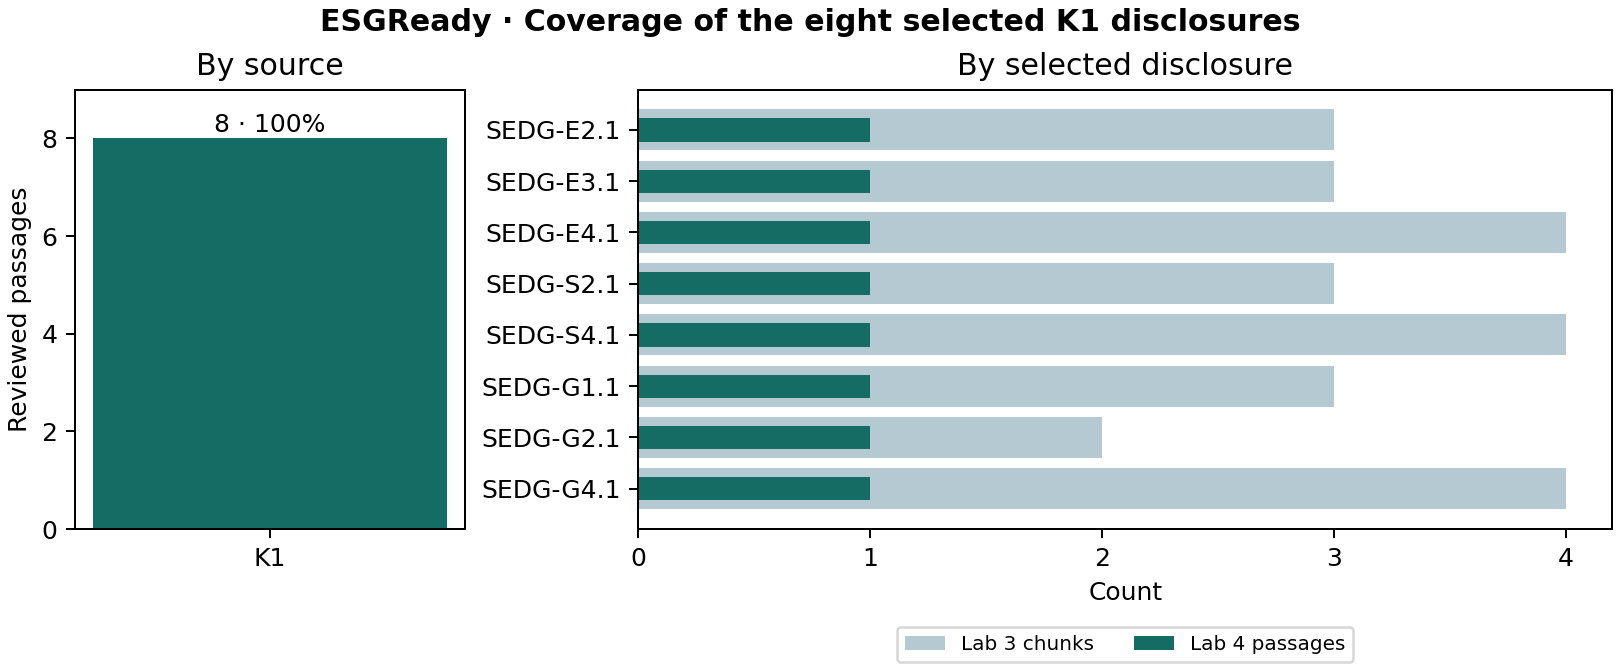

In [9]:
summary = []
for page, target in catalogue.items():
    inputs = df[df.pdf_page_1based.eq(page)]
    summary.append(dict(disclosure=target,physical_page=page,pillar=target[5],
        input_chunks=len(inputs),literal_target_chunks=int(inputs.text.str.contains(target,regex=False).sum()),
        reviewed_passages=sum(r['metadata']['reviewed_disclosure_id']==target for r in cleaned)))
coverage = pd.DataFrame(summary)
print(coverage.to_string(index=False))
counts = pd.Series([r['metadata']['source'] for r in cleaned]).value_counts()
print('Reviewed source distribution:',counts.to_dict())
fig, (left,right) = plt.subplots(1,2,figsize=(9,3.7),width_ratios=[1,2.5],layout='constrained')
left.bar(['K1'],counts.to_numpy(),color='#146c64',width=0.45)
left.set(title='By source',ylabel='Reviewed passages',ylim=(0,9))
left.text(0,8.13,'8 · 100%',ha='center')
bars = right.barh(coverage.disclosure,coverage.input_chunks,color='#b4c9d2',label='Lab 3 chunks')
right.barh(coverage.disclosure,coverage.reviewed_passages,height=.45,color='#146c64',label='Lab 4 passages')
right.invert_yaxis()
right.set(title='By selected disclosure',xlabel='Count',xticks=range(5))
right.legend(loc='upper center',bbox_to_anchor=(0.5,-0.20),ncol=2,fontsize=8)
fig.suptitle('ESGReady · Coverage of the eight selected K1 disclosures',fontweight='bold')
fig.savefig(docs/'week4_coverage_by_source.png',dpi=180)
plt.show()

### B3 · Bias and governance
| Observation and origin | How the risk could propagate | Intervention and later test |
|---|---|---|
| The source selection covers one English guide and eight disclosures. Background and case evidence are absent. | A retriever forced to choose a K1 passage could map an unsupported question to a familiar ID. A draft could mistake a reporting criterion for a company fact. | Keep D1 and D2 separate and allow abstention. In Topic 8 test scope/ambiguity handling, citation support by role and false-ready rates. |
| Extraction assigns page hints to all chunks. Eight chunks contain multiple IDs. | If hints become gold labels, retrieval may return neighbouring rules and generation may request the wrong fields. | Select the verified spans. Test mapping per disclosure, citation support and extra fields on energy, water and training cases. |
| K1 provides one dated snapshot. | If a later edition supersedes a criterion, a fluent answer could repeat the older wording. | Review the source register before indexing and record rollback. Test stale-version cases separately. Actual supersession remains unverified. |

Capital Markets Malaysia is the recorded publisher. Version, URL, pages and digest are available. The selected guidance concerns reporting categories and includes no observed personal records. Participant consent is inapplicable to this run. Publication rights remain to be verified. The project owner keeps source-derived files private pending terms, reviews revisions before indexing and removes superseded copies from active use. The formal report assigns owners, timings and residual risks.

### C2 · Reload the final pair and reconstruct its lineage
The reviewed corpus is an 8-entry D1 guidance subset. The checks below reconstruct each passage from the original export and ensure that all eight expected page/ID pairs are represented.

In [10]:
reviewed, objects = verify_pair(data/'prepared_chunks_clean.jsonl',data/'chunks_clean.pkl')
assert len(reviewed) == len(catalogue) == len({r['chunk_id'] for r in reviewed})
assert {r['metadata']['pdf_page_1based']:r['metadata']['reviewed_disclosure_id'] for r in reviewed} == catalogue
for r in reviewed:
    m = r['metadata']
    slices = []
    for parent in m['parent_spans']:
        p = df.loc[parent['record_id']]
        assert p.pdf_page_1based == m['pdf_page_1based']
        assert 0 <= parent['start'] < parent['end'] <= len(p.text)
        slices.append(p.text[parent['start']:parent['end']])
    assert r['text'] == ' '.join(''.join(slices).split())
    assert m['source_role'] == 'disclosure_guidance' and m['source_sha256'] == pdf_hash
print('8/8 passages reconstructed from parent spans with correct page, role and source digest.')
print('GO WITH CONDITIONS for the pinned guidance subset. See docs/week4_data_quality_report.md §8.')

prepared_chunks_clean.jsonl and chunks_clean.pkl: 8 records, ordered IDs, text and metadata agree.
8/8 passages reconstructed from parent spans with correct page, role and source digest.
GO WITH CONDITIONS for the pinned guidance subset. See docs/week4_data_quality_report.md §8.
